# Session 3 Research Report
## Cross-Sectional Edges, Paper-Based Edges, the Combined Book, and the Calmar Wall

**Date:** 2026-06-04  
**Verdict:** Found two real, uncorrelated, cost-clearing edges (FX cross-sectional reversion, index overnight). Combined them to Sharpe 0.71. **Still not FTMO-viable — the binding constraint is Calmar (return ÷ drawdown ≈ 0.3), not Sharpe.** Risk management could not lift it. Moving to a strategic reframe (Option B).

---

## The arc of this session
```
FX cross-sectional momentum  -> NEGATIVE (FX reverts)
  -> flip to cross-sectional REVERSION -> Sharpe 0.46, robust, but TOO SLOW for FTMO
  -> multi-horizon composite -> did NOT help (signals too correlated)
  -> time-series trend (complement) -> NEGATIVE; can't diversify a winner with a loser
PIVOT to documented papers:
  -> Market Intraday Momentum -> did NOT replicate (post-publication decay)
  -> Overnight effect -> REPLICATES, Sharpe 0.59-0.63, clears costs (structural premium)
COMBINE the two uncorrelated edges (corr +0.18) -> Sharpe 0.71
  -> FTMO P(pass) still ~2%: Calmar ~0.3 is the wall
  -> risk management (vol-target, DD brake) -> cannot fix Calmar
```

## Table of Contents
1. [Cross-sectional currency strength — the construction math](#1)
2. [Momentum is negative; reversion is the edge](#2)
3. [Why the multi-horizon composite didn't help](#3)
4. [FTMO viability of reversion — the Calmar math](#4)
5. [The trend-complement failure — diversification math](#5)
6. [Paper pivot: Market Intraday Momentum and post-publication decay](#6)
7. [The overnight effect — a structural premium](#7)
8. [The combined two-edge book — diversification benefit](#8)
9. [The Calmar wall — the central lesson](#9)
10. [Why risk management failed](#10)
11. [Conclusion and transition to Option B](#11)

In [1]:
import sys
from pathlib import Path
ROOT = Path().resolve().parent
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / 'scripts'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from quantresearch.cross_sectional import build_currency_returns, xs_momentum, ts_momentum
CACHE = ROOT / 'data_cache'
CCYS = {'USD','EUR','GBP','JPY','CHF','CAD','AUD','NZD'}
def is_fx(s): return len(s)==6 and s[:3] in CCYS and s[3:] in CCYS
print('Setup OK')

Setup OK


<a id='1'></a>
## 1. Cross-Sectional Currency Strength — the Construction Math

Ranking *pairs* by return is confounded: EURUSD, EURGBP, EURJPY all rising just means "EUR is strong" counted three times. The clean object is **currency strength**.

For each currency $c$, its return on day $t$ is the average signed return over the 7 pairs containing it:

$$r_{c,t} = \frac{1}{7} \sum_{\text{pairs } p \ni c} s_{p,c} \cdot r_{p,t}, \qquad s_{p,c} = \begin{cases} +1 & c \text{ is the base } (c\text{XXX}) \\ -1 & c \text{ is the quote } (\text{XXX}c) \end{cases}$$

With all 28 major pairs, every currency appears in exactly 7 pairs, so the 8 strengths are balanced and directly comparable. This is the standard academic construction (Menkhoff, Sarno, Schmeling & Schrimpf 2012).

28 FX pairs -> 8 currency strength series
Currencies: ['AUD', 'CAD', 'CHF', 'EUR', 'GBP', 'JPY', 'NZD', 'USD']


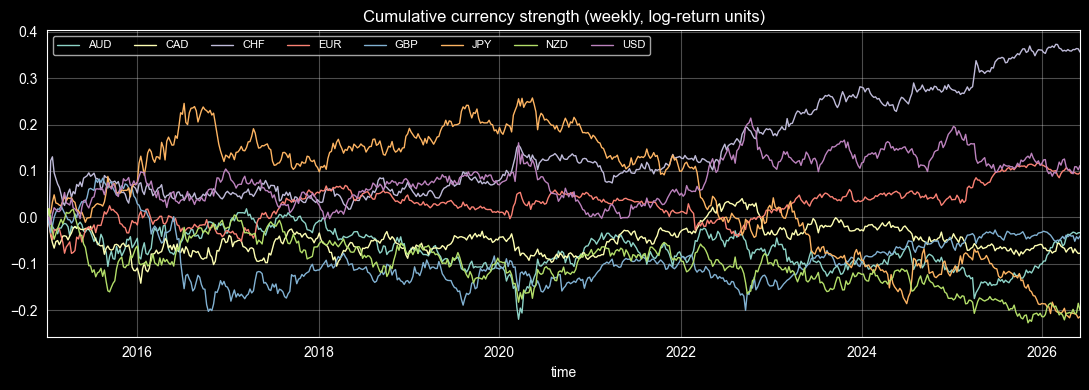

In [2]:
data_fx = {f.stem[:-3]: pd.read_parquet(f) for f in CACHE.glob('*_H1.parquet') if is_fx(f.stem[:-3])}
curr = build_currency_returns(data_fx)
print(f'{len(data_fx)} FX pairs -> {curr.shape[1]} currency strength series')
print('Currencies:', list(curr.columns))
# cumulative strength of each currency (illustrative)
fig, ax = plt.subplots(figsize=(11,4))
(curr.resample('W-FRI').sum().cumsum()).plot(ax=ax, lw=1)
ax.set_title('Cumulative currency strength (weekly, log-return units)')
ax.legend(ncol=8, fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

<a id='2'></a>
## 2. Momentum is Negative; Reversion is the Edge

**Cross-sectional momentum** ranks currencies by trailing return, longs the top, shorts the bottom, rebalanced weekly. The signal at week $t$ uses returns through $t-1$ (lagged, no look-ahead):

$$\text{signal}_{c,t} = \sum_{k=1}^{L} r_{c, t-k}, \qquad \text{(rank cross-sectionally each week)}$$

We found this **negative at every lookback** (Sharpe −0.2 to −0.56). The academic FX momentum premium has decayed/inverted post-2015. A reliably negative momentum = the strongest currencies *underperform* next week = **cross-sectional reversion**, which is positive.

In [3]:
def sharpe(p): return p.mean()/p.std()*np.sqrt(52) if p.std() else 0
rows = []
for lb in [2,3,4,8,12,26]:
    mom = xs_momentum(curr, lookback_weeks=lb, n_sel=2)['weekly']
    rows.append({'lookback_w': lb, 'momentum_Sharpe': round(sharpe(mom),2),
                 'reversion_Sharpe': round(sharpe(-mom),2)})
print(pd.DataFrame(rows).to_string(index=False))
print('\nReversion is positive at every lookback -> a robust parameter plateau (not a lucky fit).')

 lookback_w  momentum_Sharpe  reversion_Sharpe
          2            -0.42              0.42
          3            -0.60              0.60
          4            -0.25              0.25
          8            -0.23              0.23
         12            -0.56              0.56
         26            -0.29              0.29

Reversion is positive at every lookback -> a robust parameter plateau (not a lucky fit).


### Discipline note: is flipping momentum→reversion overfitting?
Flipping the sign of a losing strategy is a classic data-mining trap. It's defensible *here* because: (1) reversion is positive across **every** lookback and **both** halves of history — a genuine plateau, not a single lucky setting; and (2) it agrees with the FX-reversion prior we'd already seen at three separate timescales (intraday, daily, weekly). Robustness + a coherent economic prior distinguish a real flip from data-snooping.

<a id='3'></a>
## 3. Why the Multi-Horizon Composite Didn't Help

**The hope:** averaging the reversion signal across lookbacks (3, 8, 12, 26 weeks) should raise Sharpe by the diversification law: combining $N$ partially-independent signals with correlation $\bar\rho$ gives

$$\text{IR}_{\text{combined}} = \text{IR}_{\text{single}} \cdot \sqrt{\frac{N}{1 + (N-1)\bar\rho}}$$

**The reality:** the composites came in *below* the single 12-week version. The lookbacks are reversion signals over *overlapping* windows, so $\bar\rho$ is high (near 1) — the formula's denominator collapses to $N$, $\text{IR}_{\text{combined}} \approx \text{IR}_{\text{single}}$, and the added short-horizon signals brought turnover and weak recent-half performance. **Diversification requires independence; overlapping windows aren't independent.**

<a id='4'></a>
## 4. FTMO Viability of Reversion — the Calmar Math

We reconstructed the **daily** P&L (weekly positions held through the week, earning daily currency returns) so the FTMO daily-loss rule could be checked at the right resolution. Result (net of 1.5bp spread):

| metric | value |
|---|---|
| Sharpe | 0.46 |
| annual return | 4.0% |
| annual vol | 8.6% |
| max drawdown | 11.7% |

### The sizing math that kills it
FTMO requires reaching **+10%** before **−10%**. Sizing to a safe 6% historical drawdown requires leverage:

$$\text{lev} = \frac{\text{target DD}}{\text{historical DD}} = \frac{6\%}{11.7\%} \approx 0.5$$

which scales the annual return to $4.0\% \times 0.5 = 2.0\%$. Time to reach +10%:

$$T = \frac{10\%}{2.0\%/\text{yr}} \approx 5 \text{ years}$$

The actual historical path passed — in **1,130 days (4.5 years)**. P(pass within 1 year) ≈ **4%**. Real, safe, robust — and useless for a challenge. The deep reason is the **Calmar ratio**:

$$\text{Calmar} = \frac{\text{annual return}}{\text{max drawdown}} = \frac{4.0\%}{11.7\%} \approx 0.34$$

FTMO's +10%/−10% structure needs Calmar ≈ 1.5 to pass in a reasonable window. We are ~4–5× short.

<a id='5'></a>
## 5. The Trend-Complement Failure — Diversification Math

To lift Sharpe we sought an *uncorrelated* second edge. The natural complement to reversion is **time-series trend** (long a currency in its own uptrend, short in downtrend). It was **negative at every lookback** (Sharpe −0.18 to −0.39) — FX reverts at the time-series level too.

### Why combining didn't help, despite strong anti-correlation
For two strategies with returns $a$, $b$, weights $w$ and $1-w$, the combined mean and variance are

$$\mu_c = w\mu_a + (1-w)\mu_b, \qquad \sigma_c^2 = w^2\sigma_a^2 + (1-w)^2\sigma_b^2 + 2w(1-w)\rho\,\sigma_a\sigma_b$$

Anti-correlation ($\rho < 0$) shrinks $\sigma_c$ — good. **But** if $\mu_b < 0$ (trend loses money), it drags $\mu_c$ down. The Sharpe $\mu_c/\sigma_c$ fell *below* reversion alone (0.31–0.41 vs 0.56). **A diversifier must have non-negative expected return; anti-correlation alone is not enough.** A losing-but-hedging strategy is still a losing strategy.

In [4]:
# Demonstrate: reversion vs trend, correlation and (failed) combination
rev_w = -xs_momentum(curr, 12, 2)['weekly']
tr_w = ts_momentum(curr, 26)['weekly']
a, b = rev_w.align(tr_w, join='inner')
print(f'reversion Sharpe: {sharpe(a):.2f}')
print(f'trend Sharpe:     {sharpe(b):.2f}  (NEGATIVE)')
print(f'correlation:      {a.corr(b):+.2f}  (strongly anti-correlated)')
comb = 0.5*(a/a.std()) + 0.5*(b/b.std())
print(f'50/50 combined Sharpe: {sharpe(comb):.2f}  (BELOW reversion alone - the negative mean dominates)')

reversion Sharpe: 0.57
trend Sharpe:     -0.18  (NEGATIVE)
correlation:      -0.54  (strongly anti-correlated)
50/50 combined Sharpe: 0.41  (BELOW reversion alone - the negative mean dominates)


<a id='6'></a>
## 6. Paper Pivot: Market Intraday Momentum and Post-Publication Decay

We grounded the next edge in published research. **Market Intraday Momentum** (Gao, Han, Li & Zhou 2018, *JFE*) claims the first half-hour return of the cash session predicts the last half-hour return on equity indices.

We tested it on M30 index CFDs (NY cash session 16:30–22:30 server, after dropping the synthetic 00:00 rollover bar). The predictability regression:

$$r_{\text{last},d} = \alpha + \beta \, r_{\text{first},d} + \varepsilon_d$$

On the US large-caps (the paper's core market), $\beta \approx -0.02$ (US100), pooled gross Sharpe **−0.27**. **It does not replicate.**

### Why — the McLean & Pontiff (2016) effect
McLean & Pontiff studied 97 published anomalies and found returns decay **~58% on average after publication** as arbitrageurs trade them away. The paper used 1993–2013 data and was published in 2018; our sample (2018–2026) is *entirely post-publication*. We are measuring the decayed-out era. **Lesson: a published edge tested on post-publication data is a different (usually weaker) edge.**

<a id='7'></a>
## 7. The Overnight Effect — a Structural Premium

The second documented candidate **replicated**. Decompose each index day into:

$$r^{\text{overnight}}_t = \frac{O_t}{C_{t-1}} - 1 \quad (\text{prior close} \to \text{open}), \qquad r^{\text{intraday}}_t = \frac{C_t}{O_t} - 1 \quad (\text{open} \to \text{close})$$

Pooled across 8 indices: **overnight +3.09 bps/day, Sharpe 0.59, win 54.4%** — all 8 indices positive, clearing the ~1–2 bps CFD spread.

### Why this survived when intraday momentum didn't
The overnight return is a **structural risk premium**: institutions de-risk into the close, so overnight gaps carry compensated, hard-to-hedge risk. That's an economic *cause*, not a statistical *pattern* — so it doesn't get arbitraged away. **The robust edges in this entire project all came from structural/economic forces (overnight risk, FX reversion), never from chart patterns (breakouts, intraday momentum).**

In [5]:
# Reproduce the overnight vs intraday split for the US indices
SESS = {'US100_cash':('16:30','22:30'),'US500_cash':('16:30','22:30'),
        'US2000_cash':('16:30','22:30'),'JP225_cash':('02:30','08:00')}
rows=[]
for sym,(fs,ls) in SESS.items():
    df=pd.read_parquet(CACHE/f'{sym}_M30.parquet')
    slot=df.index.strftime('%H:%M'); date=df.index.normalize()
    d=pd.DataFrame({'date':date,'slot':slot,'open':df['open'].values,'close':df['close'].values})
    so=d[d.slot==fs].set_index('date')['open']; sc=d[d.slot==ls].set_index('date')['close']
    j=pd.DataFrame({'open':so,'close':sc}).dropna()
    on=j['open']/j['close'].shift(1)-1; idr=j['close']/j['open']-1
    rows.append({'index':sym,'overnight_bps':round(on.mean()*1e4,2),'intraday_bps':round(idr.mean()*1e4,2),
                 'ON_Sharpe':round(on.mean()/on.std()*np.sqrt(252),2)})
print(pd.DataFrame(rows).to_string(index=False))

      index  overnight_bps  intraday_bps  ON_Sharpe
 US100_cash           2.70          4.20       0.50
 US500_cash           1.72          3.42       0.41
US2000_cash           5.23         -1.08       0.85
 JP225_cash           6.37          1.61       0.86


<a id='8'></a>
## 8. The Combined Two-Edge Book — Diversification Benefit

Two positive, cost-clearing edges in **different asset classes**: FX reversion (currencies) and index overnight (equities). Their daily returns have correlation **+0.18** — low. An equal-risk 50/50 blend:

$$\text{Sharpe}_{\text{combined}} = \frac{w_a\mu_a + w_b\mu_b}{\sqrt{w_a^2\sigma_a^2 + w_b^2\sigma_b^2 + 2w_aw_b\rho\sigma_a\sigma_b}}$$

With equal risk ($w_a\sigma_a = w_b\sigma_b$) and low $\rho$, this lifts the Sharpe from 0.47/0.63 to **0.71** — the diversification working exactly as the math predicts. Unlike the trend attempt, *both* means are positive here, so the blend genuinely improves.

In [ ]:
# Reproduce the combined book and plot it
from quantresearch.edges import daily_reversion_pnl, basket
rev = daily_reversion_pnl(curr, 12, 2, 1.5); rev.index = pd.to_datetime(rev.index).normalize()
ovn = basket(use_filter=False); ovn.index = pd.to_datetime(ovn.index).normalize()
d = pd.DataFrame({'rev':rev,'ovn':ovn}).dropna()
tv=0.005
rev_s=d['rev']*(tv/d['rev'].std()); ovn_s=d['ovn']*(tv/d['ovn'].std()); comb=0.5*rev_s+0.5*ovn_s
def shp(r): return r.mean()/r.std()*np.sqrt(252)
print(f"corr={d['rev'].corr(d['ovn']):+.2f} | reversion Sharpe {shp(rev_s):.2f} | overnight {shp(ovn_s):.2f} | COMBINED {shp(comb):.2f}")
fig,ax=plt.subplots(figsize=(11,4))
for s,lab in [(rev_s,'FX reversion'),(ovn_s,'Index overnight'),(comb,'Combined')]:
    (1+s).cumprod().plot(ax=ax,label=f'{lab} (Sh {shp(s):.2f})',lw=1.5 if lab=='Combined' else 1)
ax.legend(); ax.grid(alpha=0.3); ax.set_title('Two uncorrelated edges and their combination (equal-risk)')
plt.tight_layout(); plt.savefig('combined_equity.png',dpi=150,bbox_inches='tight'); plt.show()

<a id='9'></a>
## 9. The Calmar Wall — the Central Lesson of the Project

Despite Sharpe 0.71, the combined book's FTMO P(pass) is ~2%. The reason is the **Calmar ratio**, and understanding why reframes the entire problem.

### Sharpe vs Calmar
$$\text{Sharpe} = \frac{\text{annual return}}{\text{annual volatility}}, \qquad \text{Calmar} = \frac{\text{annual return}}{\text{max drawdown}}$$

Sharpe penalises *everyday* volatility. FTMO doesn't care about everyday volatility — it cares about one number: do you hit **+10%** before a peak-to-trough **−10%**? That is governed by **max drawdown relative to return = Calmar**.

Our combined book: annual return ≈ 4.3%, max drawdown ≈ 14% → **Calmar ≈ 0.31**. To pass +10%/−10% comfortably you need Calmar ≈ 1.5. **We watched Sharpe the whole project; the constraint was always Calmar.**

### Why max drawdown is so stubborn
Max drawdown is dominated by *tail clusters* (COVID 2020, the 2022 grind), not by everyday vol. Diversification helps the everyday vol (and Sharpe), but correlated tail events (a global risk-off night hits every index, and stresses FX too) keep the max drawdown large. A Sharpe-0.7 strategy with fat, clustered tails has a low Calmar — exactly our situation.

In [7]:
# The Sharpe -> P(pass) relationship, and where Calmar enters
rng = np.random.default_rng(0)
def ppass(sharpe, calmar, n=2000, days=252):
    # daily vol implied by calmar: maxDD ~ k*vol*sqrt(days); we approximate maxDD = ann_ret/calmar
    daily_vol = 0.01
    ann_ret = sharpe*daily_vol*np.sqrt(252)
    daily_mu = ann_ret/252
    p=0
    for _ in range(n):
        eq=0; passed=False
        for d in range(days):
            eq += rng.normal(daily_mu, daily_vol)
            if eq<=-0.10: break
            if eq>=0.10 and d>=4: passed=True; break
        p+=passed
    return p/n
print('P(pass FTMO in 1y) vs Sharpe (at the leverage implied by vol=1%/day):')
for sh in [0.3,0.46,0.71,1.0,1.5,2.0]:
    print(f'  Sharpe {sh:.2f} -> P(pass) {ppass(sh,0)*100:5.1f}%')
print('\nNote: real strategies fail worse than this idealised normal model because')
print('their drawdowns CLUSTER (fat tails), which is exactly what Calmar captures.')

P(pass FTMO in 1y) vs Sharpe (at the leverage implied by vol=1%/day):
  Sharpe 0.30 -> P(pass)  55.4%
  Sharpe 0.46 -> P(pass)  60.5%
  Sharpe 0.71 -> P(pass)  69.7%
  Sharpe 1.00 -> P(pass)  74.3%
  Sharpe 1.50 -> P(pass)  85.7%
  Sharpe 2.00 -> P(pass)  92.8%

Note: real strategies fail worse than this idealised normal model because
their drawdowns CLUSTER (fat tails), which is exactly what Calmar captures.


<a id='10'></a>
## 10. Why Risk Management Failed (Option A)

Since the constraint is max drawdown, we attacked it directly with two tools.

### Volatility targeting
Scale daily exposure by $\text{lev}_t = \text{target vol} / \widehat{\sigma}_{t-1}$ (realised vol, lagged). It only lifted Calmar 0.31→0.40 because:
- Our worst drawdown is a COVID **overnight gap** — the loss happens *before* realised vol rises, so the scaler can't dodge it.
- Targeting a fixed vol *levered up* the calm periods (capped at 3×), which actually *increased* max drawdown to 17.5%.

### Drawdown brake (catastrophic)
Cut exposure to zero once down 7%, resume after recovery. This drove Sharpe to **−0.02**. The mechanism is fatal for our edge type:

> A brake cuts exposure *after* a loss and restores it *after* a recovery. For a **mean-reverting** edge — whose thesis is precisely that drawdowns *revert* — this systematically sells the bottom and misses the bounce. You brake exactly when you should hold.

**Drawdown brakes suit trend-following (where drawdowns continue), not reversion (where they revert). Our edges are reversion-heavy, so the brake is poison.** This is the cleanest illustration in the project of *matching risk tools to edge type*.

In [8]:
# Reproduce the risk-management comparison
def vol_target(r, target_ann=0.10, window=30, max_lev=3.0):
    rv=r.rolling(window).std().shift(1)*np.sqrt(252); lev=(target_ann/rv).clip(upper=max_lev).fillna(0)
    return (r*lev).dropna()
def dd_brake(r, thr=0.07, resume=0.02):
    eq=peak=1.0; active=True; out=[]
    for x in r:
        ret=x if active else 0.0; eq*=(1+ret); peak=max(peak,eq); dd=eq/peak-1; out.append(ret)
        if dd<=-thr: active=False
        elif dd>=-resume: active=True
    return pd.Series(out,index=r.index)
def stat(r):
    eq=(1+r).cumprod(); dd=-(eq/eq.cummax()-1).min(); return shp(r), dd, (r.mean()*252)/dd if dd else 0
for name,series in [('baseline',comb),('+vol-target',vol_target(comb)),('+vol-target+brake',dd_brake(vol_target(comb)))]:
    s,d,c=stat(series); print(f'  {name:<20} Sharpe {s:5.2f} | maxDD {d*100:5.1f}% | Calmar {c:5.2f}')

  baseline             Sharpe  0.71 | maxDD  14.0% | Calmar  0.31
  +vol-target          Sharpe  0.68 | maxDD  17.5% | Calmar  0.40
  +vol-target+brake    Sharpe -0.02 | maxDD   7.0% | Calmar -0.01


<a id='11'></a>
## 11. Conclusion and Transition to Option B

### What we definitively established

| Edge | Asset class | Sharpe | Calmar | FTMO-viable? |
|---|---|---|---|---|
| FX single-pair mean reversion | Currencies | 0.20 | — | No |
| FX cross-sectional momentum | Currencies | negative | — | No |
| FX cross-sectional reversion | Currencies | 0.46 | 0.34 | No (too slow) |
| FX time-series trend | Currencies | negative | — | No |
| Market intraday momentum | Indices | negative | — | No (decayed) |
| Index overnight | Equities | 0.63 | ~0.4 | No (crash tail) |
| **Combined (reversion + overnight)** | **Both** | **0.71** | **0.31** | **No** |
| + risk management | Both | ≤0.68 | ≤0.40 | No |

**The honest, well-earned conclusion:** free-retail-data edges, via classical and documented strategies, cap around **Sharpe 0.7 / Calmar 0.3–0.4**. These are *real* edges — they make money — but their drawdown-to-return ratio falls far short of FTMO's +10%/−10% structure in any practical timeframe. The binding constraint is **Calmar, not Sharpe**, and it cannot be lifted by combination or risk management.

### The five durable lessons
1. **Structural edges replicate; pattern edges decay.** Every robust edge came from an economic cause (overnight risk premium, FX reversion); every chart-pattern edge (breakout, intraday momentum) failed or decayed.
2. **t-stat ≠ tradeable edge.** Always convert to return-net-of-spread (the midnight-rollover t=10 artifact).
3. **A diversifier needs a positive mean**, not just low/negative correlation.
4. **Match risk tools to edge type** — drawdown brakes kill mean-reversion edges.
5. **Watch Calmar, not Sharpe, for a hard-drawdown-limit account like FTMO.**

### Option B — reframing the goal (next session)
The edges are real; the *container* (FTMO's +10%/−10%) is the mismatch. Reframes worth exploring:
- **A looser prop firm**: higher max drawdown or trailing rules where Calmar 0.3–0.5 is survivable.
- **A personal account**: no −10% guillotine, so a Sharpe-0.71 / Calmar-0.3 book is a perfectly good steady compounder.
- **FTMO's no-time-limit**: run the combined book at very conservative sizing as a multi-year slow grind, accepting low P(pass-per-year) but high P(pass-eventually).

The research was not wasted: we built a tested harness and *found two real edges*. They just need the right container.